# How AI Can Be Dangerous:


| # | Risk | What we show |
|---|------|--------------|
| 1 | **Bias & discrimination** | A model learns unfair rules from biased data |
| 2 | **Adversarial attacks** | Tiny invisible changes fool a model |
| 3 | **Data poisoning** | Corrupting training data ruins a model |
| 4 | **Overconfidence** | A model is 99% sure about pure noise |

Run the cells from top to bottom (Runtime -> Run all). Everything runs on the free Colab CPU.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (8, 4)
print("Setup done")

Setup done


---
## Danger 1: Bias and Discrimination

AI learns from historical data. If the past decisions were unfair, the AI **copies and automates the unfairness**.

We create a fake hiring dataset where past managers penalised **Group B** even when skills were equal.

In [ ]:
rng = np.random.default_rng(42)
n = 6000
group = rng.integers(0, 2, n)          # 0 = Group A, 1 = Group B
skill = rng.normal(0, 1, n)
experience = rng.normal(0, 1, n)

# Biased historical decisions: Group B gets a penalty
score = 1.0 * skill + 0.8 * experience - 1.2 * group + rng.normal(0, 0.5, n)
hired = (score > 0).astype(int)

df = pd.DataFrame({"skill": skill, "experience": experience, "group": group, "hired": hired})
print(df.groupby("group")["hired"].mean().rename({0: "Group A", 1: "Group B"}).to_frame("Historical hire rate"))

         Historical hire rate
group                        
Group A              0.501656
Group B              0.203356


Accuracy: 0.898 (looks great!)
Learned weights: {'skill': np.float64(3.34), 'experience': np.float64(2.68), 'group': np.float64(-4.05)}

Same skills -> hire probability  Group A: 96% | Group B: 28%


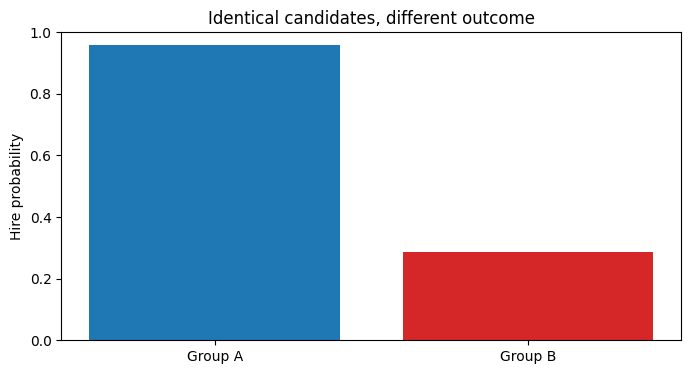

In [ ]:
X = df[["skill", "experience", "group"]]
y = df["hired"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)

model = LogisticRegression().fit(Xtr, ytr)
print("Accuracy:", round(model.score(Xte, yte), 3), "(looks great!)")
print("Learned weights:", dict(zip(X.columns, model.coef_[0].round(2))))

# Two IDENTICAL candidates, only the group differs
twins = pd.DataFrame({"skill": [0.5, 0.5], "experience": [0.5, 0.5], "group": [0, 1]})
p = model.predict_proba(twins)[:, 1]
print(f"\nSame skills -> hire probability  Group A: {p[0]:.0%} | Group B: {p[1]:.0%}")

plt.bar(["Group A", "Group B"], p, color=["tab:blue", "tab:red"])
plt.ylabel("Hire probability"); plt.title("Identical candidates, different outcome")
plt.ylim(0, 1); plt.show()

**Lesson:** The model has high accuracy, yet it is discriminating. Accuracy alone does not prove an AI is fair. Real cases include biased hiring tools, loan scoring and face recognition.

---
## Danger 2: Adversarial Attacks (Fooling AI)

We train a digit classifier, then apply the **FGSM attack**: add a tiny, nearly invisible change to the image that pushes the model toward a wrong answer. This is a real concern for self-driving cars, face unlock and medical imaging.

In [ ]:
digits = load_digits()
Xd = (digits.data / 16.0).astype(np.float32)   # pixels in [0, 1]
yd = digits.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=0)

Xt_tr, yt_tr = torch.tensor(Xd_tr), torch.tensor(yd_tr)
Xt_te, yt_te = torch.tensor(Xd_te), torch.tensor(yd_te)

net = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
opt = torch.optim.Adam(net.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(150):
    opt.zero_grad()
    loss = loss_fn(net(Xt_tr), yt_tr)
    loss.backward()
    opt.step()

acc = (net(Xt_te).argmax(1) == yt_te).float().mean().item()
print(f"Clean test accuracy: {acc:.1%}")

Clean test accuracy: 96.5%


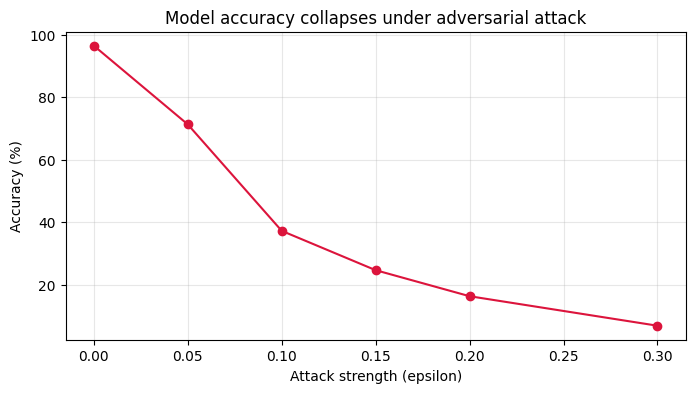

eps=0     accuracy=96.5%
eps=0.05  accuracy=71.3%
eps=0.1   accuracy=37.2%
eps=0.15  accuracy=24.6%
eps=0.2   accuracy=16.3%
eps=0.3   accuracy=6.9%


In [ ]:
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    loss = loss_fn(model(x), y)
    loss.backward()
    return (x + eps * x.grad.sign()).clamp(0, 1).detach()

epsilons = [0, 0.05, 0.1, 0.15, 0.2, 0.3]
accs = []
for e in epsilons:
    x_adv = fgsm(net, Xt_te, yt_te, e)
    accs.append((net(x_adv).argmax(1) == yt_te).float().mean().item())

plt.plot(epsilons, [a * 100 for a in accs], marker="o", color="crimson")
plt.xlabel("Attack strength (epsilon)"); plt.ylabel("Accuracy (%)")
plt.title("Model accuracy collapses under adversarial attack"); plt.grid(alpha=.3); plt.show()
for e, a in zip(epsilons, accs): print(f"eps={e:<5} accuracy={a:.1%}")

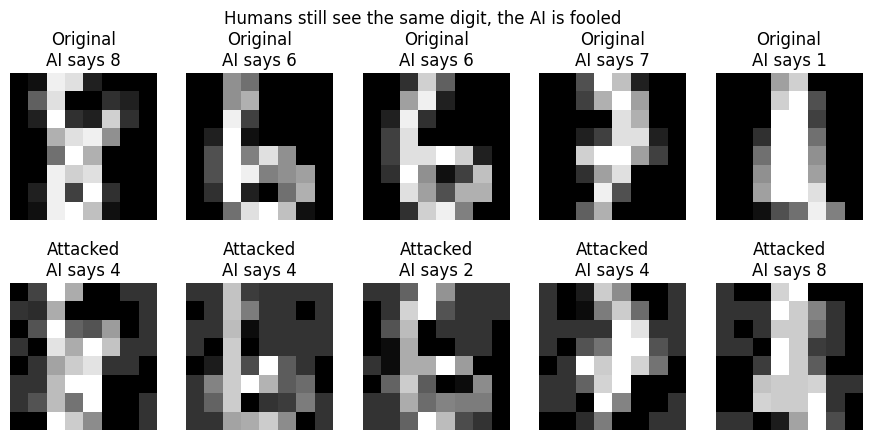

In [ ]:
eps = 0.2
x_adv = fgsm(net, Xt_te, yt_te, eps)
pred_clean = net(Xt_te).argmax(1)
pred_adv = net(x_adv).argmax(1)

idx = [i for i in range(len(yt_te)) if pred_clean[i] == yt_te[i] and pred_adv[i] != yt_te[i]][:5]
fig, ax = plt.subplots(2, len(idx), figsize=(2.2 * len(idx), 5))
for j, i in enumerate(idx):
    ax[0, j].imshow(Xt_te[i].reshape(8, 8), cmap="gray"); ax[0, j].set_title(f"Original\nAI says {pred_clean[i].item()}"); ax[0, j].axis("off")
    ax[1, j].imshow(x_adv[i].reshape(8, 8), cmap="gray"); ax[1, j].set_title(f"Attacked\nAI says {pred_adv[i].item()}"); ax[1, j].axis("off")
plt.suptitle("Humans still see the same digit, the AI is fooled"); plt.show()

---
## Danger 3: Data Poisoning

If an attacker can tamper with training data (scraped web data, user uploads, crowdsourced labels), they can quietly **sabotage the model**. Here we flip a percentage of the training labels.

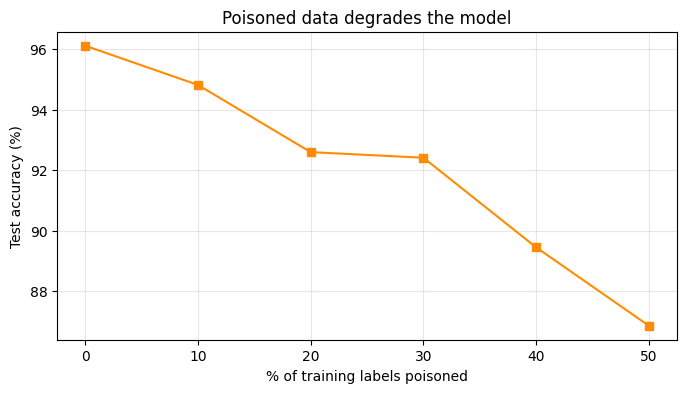

0% poisoned -> 96.1% accuracy
10% poisoned -> 94.8% accuracy
20% poisoned -> 92.6% accuracy
30% poisoned -> 92.4% accuracy
40% poisoned -> 89.4% accuracy
50% poisoned -> 86.9% accuracy


In [ ]:
fractions = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
results = []
for f in fractions:
    y_poison = yd_tr.copy()
    k = int(f * len(y_poison))
    idx = np.random.choice(len(y_poison), k, replace=False)
    y_poison[idx] = np.random.randint(0, 10, k)          # corrupt labels
    clf = LogisticRegression(max_iter=2000).fit(Xd_tr, y_poison)
    results.append(clf.score(Xd_te, yd_te))

plt.plot([f * 100 for f in fractions], [r * 100 for r in results], marker="s", color="darkorange")
plt.xlabel("% of training labels poisoned"); plt.ylabel("Test accuracy (%)")
plt.title("Poisoned data degrades the model"); plt.grid(alpha=.3); plt.show()
for f, r in zip(fractions, results): print(f"{f:.0%} poisoned -> {r:.1%} accuracy")

---
## Danger 4: Overconfidence on Things It Has Never Seen

AI models do not know what they don't know. Let's show our digit model **pure random noise**.

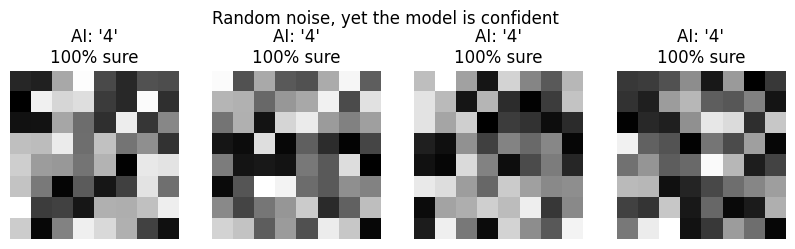

Average confidence on noise: 100%


In [ ]:
noise = torch.rand(8, 64)                       # random static, not a digit
with torch.no_grad():
    probs = torch.softmax(net(noise), dim=1)
conf, pred = probs.max(1)

fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for i in range(4):
    ax[i].imshow(noise[i].reshape(8, 8), cmap="gray"); ax[i].axis("off")
    ax[i].set_title(f"AI: '{pred[i].item()}'\n{conf[i].item():.0%} sure")
plt.suptitle("Random noise, yet the model is confident"); plt.show()
print("Average confidence on noise:", f"{conf.mean().item():.0%}")

---
## Summary of Findings

| Risk | What we saw | Real-world impact |
|------|-------------|-------------------|
| Bias | Identical candidates got different scores | Unfair hiring, loans, policing |
| Adversarial attacks | Accuracy collapsed with tiny changes | Self-driving, security, medical AI |
| Data poisoning | Corrupt labels ruined accuracy | Sabotaged models, misinformation |
| Overconfidence | High certainty about meaningless noise | Wrong decisions with no warning |

## How to Make AI Safer
- **Audit data and models for bias** (fairness metrics, remove proxy features)
- **Adversarial training** and input validation
- **Clean and verify data sources**; monitor for poisoning
- **Uncertainty estimation** and "I don't know" options
- **Human oversight** for high-stakes decisions
- **Regulation, transparency and explainability**

## Conclusion
AI is not dangerous because it is "evil". It is dangerous because it is **powerful, fragile, and only as good as its data and design**. Responsible development matters as much as capability.